In [1]:
import numpy  as np
import pandas as pd
import os

from libraries import energy_lookup, plotting, surfaces

/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


# Rank the slabs by surface free energy

In [2]:
# Define name to reference folder which stores the energies of each slab
slab_folder = '/Users/cibran/Desktop/estruturas2/LaN/slab_v0'

# ML-IAP used for every energy that is not read from a DFT calculation (vasprun.xml)
model_load_path = 'mace-mpa-0-medium.model'
device          = 'cpu'    # switch to 'cuda' if a GPU is available

# Leave out slabs whose composition differs from the bulk from the ranking and the plot
only_stoichiometric = False

The surface energy of formation ($\gamma$) is built from free (Gibbs) energies: the free energy of the slab ($G_{slab}$) and the free
energy of the bulk per formula unit ($g_{bulk}$) times the number of formula units in the slab ($N$), per unit of surface area ($A$):

\begin{equation}
    \gamma = \frac{G_{slab} - N g_{bulk}}{2 A}
\end{equation}

This first ranking is the **0 K** level, where $G = E_0$ is the total energy of the relaxed structure (no zero-point energy, no entropy).
The finite-temperature ranking at the end of the notebook uses the same expression with $G(T)$. Free energies are in eV, $A$ is in Å²
and $\gamma$ is reported in **J/m²**. The factor of 2 assumes equivalent top and bottom terminations (for asymmetric slabs
$\gamma$ is the average of both), and $N g_{bulk}$ is the bulk free energy per atom times the number of atoms of the slab, which
requires a stoichiometric slab.

In [3]:
bulk_folder = f'{slab_folder}/bulk'

slab_names = sorted(name for name in os.listdir(slab_folder)
                    if name != 'bulk' and os.path.isdir(f'{slab_folder}/{name}'))

# All the energies in the ranking must be at the same level of theory (do not mix DFT and ML-IAP)
energy_lookup.check_energy_sources([bulk_folder] + [f'{slab_folder}/{name}' for name in slab_names],
                         label='surface-energy ranking', model_load_path=model_load_path)

# Load the bulk energy
bulk_energy = energy_lookup.read_energy(bulk_folder, model_load_path=model_load_path, device=device)

# Load bulk information
bulk_data = surfaces.load_json(filename=f'{bulk_folder}/slab_data.json')
n_bulk    = bulk_data['number_of_sites']

Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [4]:
# Iterate over slabs
rows = {}
for i, miller_index_str in enumerate(slab_names):
    # Define current folder
    miller_folder = f'{slab_folder}/{miller_index_str}'

    # Load slab information
    slab_data = surfaces.load_json(filename=f'{miller_folder}/slab_data.json')

    print()
    print(f'Slab {i+1}: {miller_index_str}')
    print()
    print(f"Miller index: {slab_data['miller_index']}")
    print(f"Shift: {slab_data['shift']:.3g}")
    print(f"Surface area: {slab_data['surface_area']:.3g}")
    print(f"Number of sites: {slab_data['number_of_sites']}")

    # Load the single-shot energy (total energy of the relaxed slab, in eV)
    slab_energy = energy_lookup.read_energy(miller_folder, model_load_path=model_load_path, device=device)

    print(f'E_total = {slab_energy:.3g} eV')

    # Bulk energy scaled to the number of atoms of the slab
    bulk_energy_times_fu = bulk_energy * slab_data['number_of_sites'] / n_bulk

    # Compute surface energy of formation in J/m²
    surface_energy_of_formation = surfaces.get_surface_energy_of_formation(slab_energy, bulk_energy_times_fu, slab_data['surface_area'])

    # Save the slab energy
    np.savetxt(f'{miller_folder}/surface_energy_of_formation', [surface_energy_of_formation])

    print(f'\tE_surface = {surface_energy_of_formation:.3g} J/m²')

    rows[miller_index_str] = {
        'surface_energy_J_m2': surface_energy_of_formation,
        'miller_index':        str(slab_data['miller_index']),
        'shift':               slab_data['shift'],
        'surface_area_A2':     slab_data['surface_area'],
        'number_of_sites':     slab_data['number_of_sites'],
        'symmetric':           slab_data.get('is_symmetric', 'unknown'),
        'polar':               slab_data.get('is_polar', 'unknown'),
        'stoichiometric':      slab_data.get('is_stoichiometric', 'unknown'),
    }

summary = pd.DataFrame(rows).T
summary['surface_energy_J_m2'] = summary['surface_energy_J_m2'].astype(float)


Slab 1: 0_0_1_i_2

Miller index: [0, 0, 1]
Shift: 0.205
Surface area: 15.7
Number of sites: 16
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


E_total = -127 eV
	E_surface = 0.438 J/m²

Slab 2: 0_0_1_i_3

Miller index: [0, 0, 1]
Shift: 0.455
Surface area: 15.7
Number of sites: 16
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
E_total = -120 eV
	E_surface = 3.93 J/m²

Slab 3: 1_0_0_i_0

Miller index: [1, 0, 0]
Shift: 0.5
Surface area: 23.6
Number of sites: 24
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=F

E_total = -186 eV
	E_surface = 1.86 J/m²

Slab 4: 1_0_0_i_1

Miller index: [1, 0, 0]
Shift: 1
Surface area: 23.6
Number of sites: 24
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


... (121 outputs left out)

/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


E_total = -946 eV
	E_surface = 0.704 J/m²

Slab 67: 3_3_2_i_63

Miller index: [3, 3, 2]
Shift: 0.137
Surface area: 126
Number of sites: 120
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/cibran/work/UPC/SurfAIcing/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


E_total = -945 eV
	E_surface = 0.746 J/m²


**How to read the ranking.** Asymmetric slabs (`symmetric = False`) are ranked by the average of their two different
terminations, and non-stoichiometric slabs (`stoichiometric = False`) are ranked with a stoichiometric bulk reference, which
is not meaningful without chemical potentials. A negative surface energy usually means that the bulk reference is not
at the same level of theory as the slabs (e.g. an unrelaxed bulk).

In [5]:
n_asymmetric        = int((summary['symmetric'] == 'False').sum())
n_nonstoichiometric = int((summary['stoichiometric'] == 'False').sum())
n_invalid           = int(summary['surface_energy_J_m2'].isna().sum())
if n_asymmetric:
    print(f'[note] {n_asymmetric} slab(s) are asymmetric: their surface energy is the average of two different terminations.')
if n_nonstoichiometric:
    print(f'[note] {n_nonstoichiometric} slab(s) are not stoichiometric: their surface energy depends on the chemical potentials.')
if n_invalid:
    print(f'[warning] {n_invalid} slab(s) have no valid energy and are left out of the ranking.')

ranking = summary.dropna(subset=['surface_energy_J_m2'])
if only_stoichiometric:
    ranking = ranking[ranking['stoichiometric'] != 'False']

# Sorted data with all the flags, for inspection
ranking = ranking.sort_values(by='surface_energy_J_m2', ascending=True)
ranking.to_excel(f'{slab_folder}/sorted_data.xlsx')
ranking

[note] 58 slab(s) are asymmetric: their surface energy is the average of two different terminations.


,surface_energy_J_m2,miller_index,shift,surface_area_A2,number_of_sites,symmetric,polar,stoichiometric
0_0_1_i_2,0.438062,"[0, 0, 1]",0.205,15.652736,16,False,False,True
1_1_0_i_4,0.638866,"[1, 1, 0]",0.5,40.834859,40,True,False,True
3_2_0_i_35,0.650348,"[3, 2, 0]",0.0,102.765476,96,True,False,True
2_1_0_i_9,0.655313,"[2, 1, 0]",0.0,62.376278,64,True,False,True
3_1_0_i_29,0.664959,"[3, 1, 0]",0.166667,85.00454,84,True,False,True
...,...,...,...,...,...,...,...,...
1_0_2_i_15,1.745570,"[1, 0, 2]",0.205,39.190065,40,False,False,True
1_0_0_i_0,1.861869,"[1, 0, 0]",0.5,23.576019,24,True,False,True
1_0_1_i_6,2.228444,"[1, 0, 1]",0.455,28.29906,28,False,False,True
1_1_2_i_22,2.261496,"[1, 1, 2]",0.455,51.45404,48,False,False,True


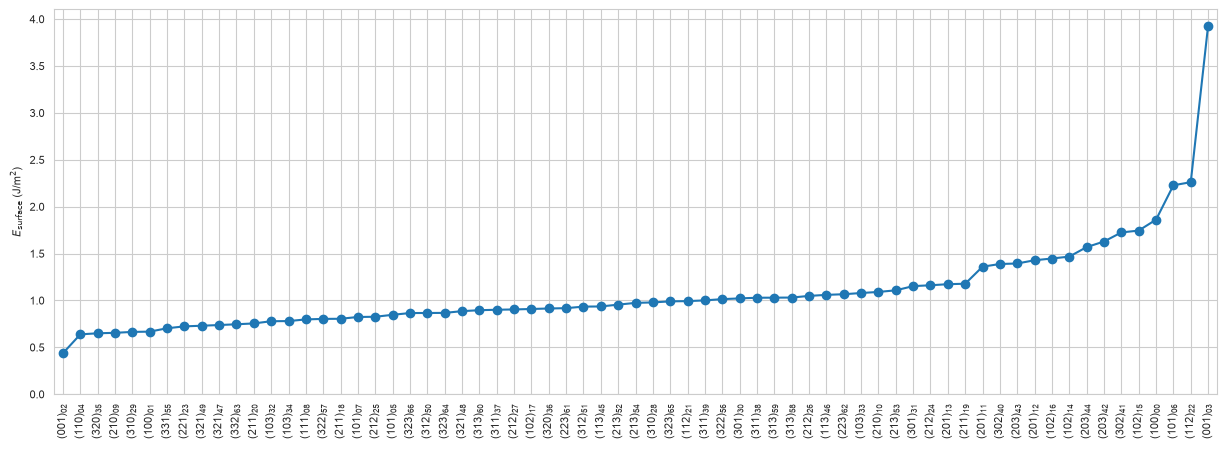

In [6]:
import seaborn as sns
sns.set_style("whitegrid")

# plot_ranking expects a one-row DataFrame ('energy') with one column per slab
surface_energies_of_formation = pd.DataFrame(ranking['surface_energy_J_m2'].to_dict(), index=['energy'])

plotting.plot_ranking(surface_energies_of_formation,
                 ylabel=r'$E_{\text{surface}}$ (J/m$^2$)',
                 filename=f'{slab_folder}/ranking.png', dpi=300)

# Finite-temperature ranking (optional)

The ranking above is the 0 K level of the free energy, $G = E_0$. At temperature $T$ the surfaces are compared with the same
expression, using the free energies of the slab and of the bulk at that temperature and the area of the runs:

\begin{equation}
    \gamma(T) = \frac{G_{slab}(T) - N g_{bulk}(T)}{2 A(T)}, \qquad G(T) = U_0(T) + F_{vib}(T)
\end{equation}

$G$ is a sum of contributions: today $U_0$ and $F_{vib}$, and further terms can be added without changing the formula for $\gamma$.
Both $G_{slab}$ and $g_{bulk}$ come from NPT runs of the slab and of the bulk (the `md/<T>K` folders made in `generate-slabs`).
With the effective-harmonic scheme (Hellman *et al.*, PRB 87, 104111 (2013)), per atom,

\begin{equation}
    U_0 = \frac{\langle U_{MD}\rangle}{N_{atoms}} - \frac{(3N_{atoms}-3)\,k_B T}{2 N_{atoms}}, \qquad
    F_{vib} = \int g(\omega)\left[\frac{\hbar\omega}{2} + k_B T \ln\left(1 - e^{-\hbar\omega/k_B T}\right)\right] d\omega
\end{equation}

where $g(\omega)$ is the vibrational density of states of the run, from the velocity autocorrelation, normalised to three modes per
atom, and $A(T)$ is the mean area of the slab cell in the run.

$E_0$ is **not** part of $G(T)$: $U_0$ comes straight from the NPT run. $E_0$ only defines the 0 K column of the table.
The columns `excess_U0_eV` and `excess_Fvib_eV` are the contributions of the two terms to the numerator of $\gamma(T)$, slab minus bulk
($2A\gamma(T)$ = `excess_U0_eV` + `excess_Fvib_eV`, before the conversion to J/m²).

The ranking is evaluated at the **operating temperature** `operating_T`, which does not have to be an MD temperature. $F_{vib}$ is
the only term evaluated at `operating_T`: it is computed exactly there from the vibrational spectrum of the MD run closest in
temperature, and $U_0$ and $A$ are those of that run. This assumes that the phonons (and $U_0$, $A$) do not change between the
temperature of the run and `operating_T`, a small approximation for a modest difference; a flag is raised when they differ by more
than 1 K, so run the MD at the temperature you need to remove the assumption. The first picoseconds of every run are discarded as thermalisation: the `md_equil_ps` set in `generate-slabs`, which is stored in the
`md.json` of each run (change it there and run that cell again to update the existing folders).

The energies of the runs must come from the same level of theory as the 0 K ones (warnings are printed otherwise). Runs
made with VASP are read from the `vasprun.xml` in their folder; their velocities are taken from the positions.

In [7]:
from IPython.display import display

from libraries import thermal

finite_temperature = False   # True: also rank by free energy (needs the md/<T>K folders made in generate-slabs)
operating_T        = 300     # K, temperature of the ranking; it does not have to be an MD temperature
run_md             = False   # True: run here, with the ML-IAP, the NPT runs that are pending or unfinished (slow; use a GPU)
vdos_max_lag_ps    = 4.0     # ps of velocity autocorrelation used for the vibrational spectrum

In [8]:
if not finite_temperature:
    print('finite_temperature = False: only the 0 K ranking is computed; no MD is run or read. '
          'Set finite_temperature = True (and run_md = True to run the pending NPT runs here).')
else:
    if run_md:
        thermal.run_pending_md(slab_folder, model_load_path=model_load_path, device=device)

    md_status = thermal.md_status(slab_folder)
    if md_status.empty:
        print(f'[warning] no md/<T>K folder found under {slab_folder}: generate them in generate-slabs '
              f'(finite_temperature = True) for this same slab_v<i> folder (a new run of generate-slabs makes a new slab_v<i>).')
    else:
        print(md_status['state'].value_counts().to_string())
        not_run = md_status['state'].isin(['pending', 'unfinished'])
        if not_run.any() and not run_md:
            print(f'\n[note] {int(not_run.sum())} NPT run(s) are planned but have not been run: this notebook only runs them with run_md = True '
                  f'(slow on a CPU; use a GPU), or run them with VASP.')
        if (md_status['state'] != 'done').any():
            print('\nRuns that are not finished are left out of the free-energy ranking:')
            display(md_status[md_status['state'] != 'done'])

finite_temperature = False: only the 0 K ranking is computed; no MD is run or read. Set finite_temperature = True (and run_md = True to run the pending NPT runs here).


In [9]:
ranking_T = None
if finite_temperature:
    try:
        ranking_T = thermal.surface_free_energy_ranking(slab_folder, operating_T, model_load_path=model_load_path, device=device,
                                                        vdos_max_lag_ps=vdos_max_lag_ps,
                                                        only_stoichiometric=only_stoichiometric)
    except thermal.MissingData as exc:
        print(f'[warning] the free-energy ranking needs a finished bulk run: {exc}')

    if ranking_T is not None:
        n_without = int(ranking_T['surface_energy_T_J_m2'].isna().sum())
        if n_without:
            print(f'[warning] {n_without} slab(s) have no finished MD run and are left out of the finite-temperature ranking.')
        ranking_T.to_excel(f'{slab_folder}/sorted_data_{operating_T:g}K.xlsx')
        display(ranking_T)

In [10]:
if ranking_T is not None:
    plotting.plot_ranking_comparison(ranking_T, filename=f'{slab_folder}/ranking_{operating_T:g}K.png', dpi=300)